In [1]:
import glob
import os
import numpy as np

import pandas as pd
import geopandas as gpd
import xarray as xr

import matplotlib.pyplot as plt
import matplotlib as mpl
import cartopy.crs as ccrs
from matplotlib.colors import ListedColormap

import memory_profiler

import GRSdriver
from GRSdriver import driver_S2_SAFE as S2

%load_ext memory_profiler

opj = os.path.join

GRSdriver.__version__

'2.0.0'

In [2]:

imageSAFE ='/data/satellite/S2/cnes/S2B_MSIL1C_20220811T100559_N0400_R022_T31NDH_20220811T171744.SAFE'
imageSAFE ='/home/harmel/Dropbox/Dropbox/satellite/S2/L1C/S2B_MSIL1C_20230711T030529_N0509_R075_T49QDB_20230711T054244.SAFE'

In [3]:
GRSdriver.driver_S2_SAFE.INFO

bandId,0,1,2,3,4,5,6,7,8,9,10,11,12
ESA,B01,B02,B03,B04,B05,B06,B07,B08,B8A,B09,B10,B11,B12
name,CA,BLUE,GREEN,RED,VRE_1,VRE_2,VRE_3,NIR,NARROW_NIR,WV,SWIR_CIRRUS,SWIR_1,SWIR_2
Wavelength (nm),443,490,560,665,705,740,783,842,865,945,1375,1610,2190
Band width (nm),20,65,35,30,15,15,20,115,20,20,30,90,180
Resolution (m),60,10,10,10,20,20,20,10,20,60,60,20,20


In [4]:
bandIds = [0,1,2,3,8,11]
resolution=60

In [5]:
l1c = S2.Sentinel2Driver(imageSAFE,band_idx=bandIds,resolution=resolution)

In [6]:
%time %memit l1c.load_geom()

peak memory: 1273.84 MiB, increment: 933.24 MiB
CPU times: user 16.9 s, sys: 1.88 s, total: 18.7 s
Wall time: 3.47 s


In [7]:
l1c.geom

<xarray.Dataset> Size: 174MB
Dimensions:      (wl: 6, y: 1830, x: 1830)
Coordinates:
  * y            (y) float64 15kB 2.2e+06 2.2e+06 2.2e+06 ... 2.09e+06 2.09e+06
  * x            (x) float64 15kB 4e+05 4e+05 4.001e+05 ... 5.097e+05 5.098e+05
    spatial_ref  int64 8B 0
Dimensions without coordinates: wl
Data variables:
    vza          (wl, y, x) float32 80MB 1.91 1.913 1.915 ... 11.13 11.13 11.14
    raa          (wl, y, x) float32 80MB 127.0 127.1 127.2 ... 214.1 214.1 214.1
    sza          (y, x) float32 13MB 19.41 19.41 19.41 ... 18.6 18.59 18.59

In [8]:
%time %memit l1c.load_bands()

peak memory: 1951.12 MiB, increment: 762.95 MiB
CPU times: user 2min 57s, sys: 6.59 s, total: 3min 4s
Wall time: 15.6 s


In [9]:
%time %memit l1c.load_product()

peak memory: 2097.96 MiB, increment: 640.23 MiB
CPU times: user 3min 14s, sys: 8.46 s, total: 3min 22s
Wall time: 18.7 s


In [10]:
l1c.prod

<xarray.Dataset> Size: 255MB
Dimensions:      (x: 1830, y: 1830, wl: 6, wl_hr: 1950)
Coordinates:
  * x            (x) float64 15kB 4e+05 4e+05 4.001e+05 ... 5.097e+05 5.097e+05
  * y            (y) float64 15kB 2.2e+06 2.2e+06 2.2e+06 ... 2.09e+06 2.09e+06
  * wl           (wl) object 48B 443 490 560 665 865 1610
  * wl_hr        (wl_hr) int64 16kB 400 401 402 403 404 ... 2346 2347 2348 2349
    spatial_ref  int64 8B 0
    time         datetime64[ns] 8B 2023-07-11T03:05:29
Data variables:
    bands        (wl, y, x) float32 80MB 0.1285 0.1282 0.1277 ... 0.1071 0.1084
    SRF          (wl, wl_hr) float64 94kB nan nan nan nan ... nan nan nan nan
    wl_true      (wl) float64 48B 442.2 492.4 558.9 664.9 864.0 1.61e+03
    vza          (wl, y, x) float32 80MB 1.91 1.913 1.915 ... 11.13 11.13 11.14
    raa          (wl, y, x) float32 80MB 127.0 127.1 127.2 ... 214.1 214.1 214.1
    sza          (y, x) float32 13MB 19.41 19.41 19.41 ... 18.6 18.59 18.59
Attributes: (12/49)
    long_name:                           CA BLUE GREEN RED NARROW_NIR SWIR_1
    constellation:                       Sentinel-2
    constellation_id:                    S2
    product_path:                        /home/harmel/Dropbox/Dropbox/satelli...
    product_name:                        S2B_MSIL1C_20230711T030529_N0509_R07...
    instrument:                          MSI
    ...                                  ...
    tile:                                49QDB
    solar_irradiance:                    [1874.3  1959.75 1824.93 1512.79 142...
    solar_irradiance_unit:               W/m²/µm
    mean_solar_azimuth:                  78.17671720226842
    mean_solar_zenith_angle:             18.99610415879017
    acquisition_date:                    2023-07-11T03:05:29.024Z

In [11]:
l1c.prod.bands.isel(wl=[3,2,1]).rio.reproject(dst_crs=4326)#.plot.imshow(rgb='wl',robust=True)

<xarray.DataArray 'bands' (wl: 3, y: 1786, x: 1883)> Size: 40MB
array([[[       nan,        nan,        nan, ..., 0.14511667,
         0.14722222, 0.14776944],
        [       nan,        nan,        nan, ..., 0.14624168,
         0.14656389, 0.14614443],
        [       nan,        nan,        nan, ..., 0.14479443,
         0.14884722, 0.14708889],
        ...,
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan]],

       [[       nan,        nan,        nan, ..., 0.155125  ,
         0.15512778, 0.15648611],
        [       nan,        nan,        nan, ..., 0.15576111,
         0.15581667, 0.15614444],
        [       nan,        nan,        nan, ..., 0.1538889 ,
         0.15770833, 0.15596944],
...
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan]],

       [[       nan,        nan,        nan, ..., 0.17585556,
         0.17614168, 0.17741944],
        [       nan,        nan,        nan, ..., 0.17591389,
         0.17704722, 0.17736667],
        [       nan,        nan,        nan, ..., 0.17445   ,
         0.17634167, 0.17741944],
        ...,
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan]]], shape=(3, 1786, 1883), dtype=float32)
Coordinates:
  * wl           (wl) object 24B 665 560 490
  * y            (y) float64 14kB 19.9 19.9 19.9 19.89 ... 18.9 18.9 18.9 18.9
  * x            (x) float64 15kB 110.0 110.0 110.0 110.0 ... 111.1 111.1 111.1
    time         datetime64[ns] 8B 2023-07-11T03:05:29
    spatial_ref  int64 8B 0

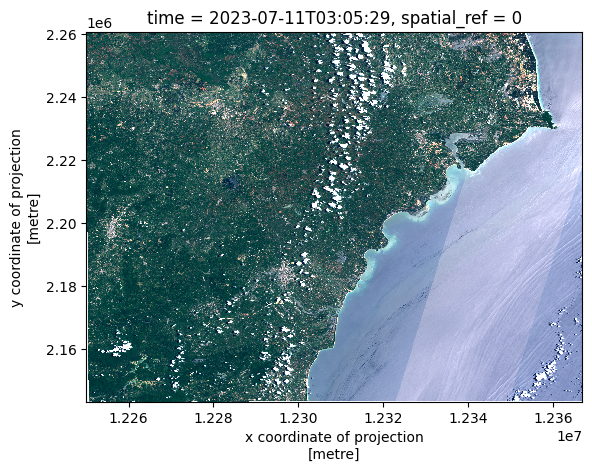

In [12]:
l1c.prod.bands.isel(wl=[3,2,1]).rio.reproject(dst_crs=3857).plot.imshow(rgb='wl',robust=True)

EPSG:32649


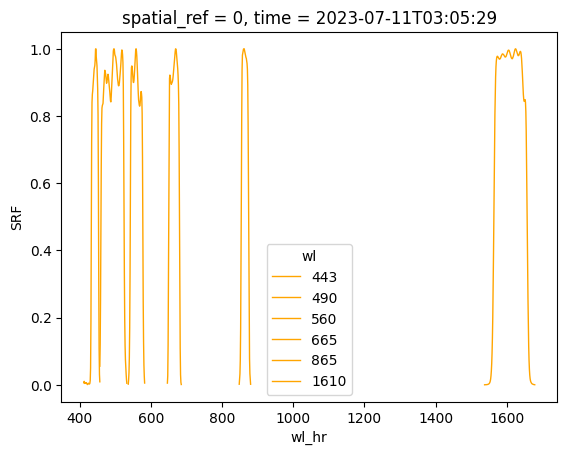

In [13]:
print(l1c.prod.rio.crs)
l1c.prod.SRF.plot(x='wl_hr',hue='wl',color='orange',lw=1)

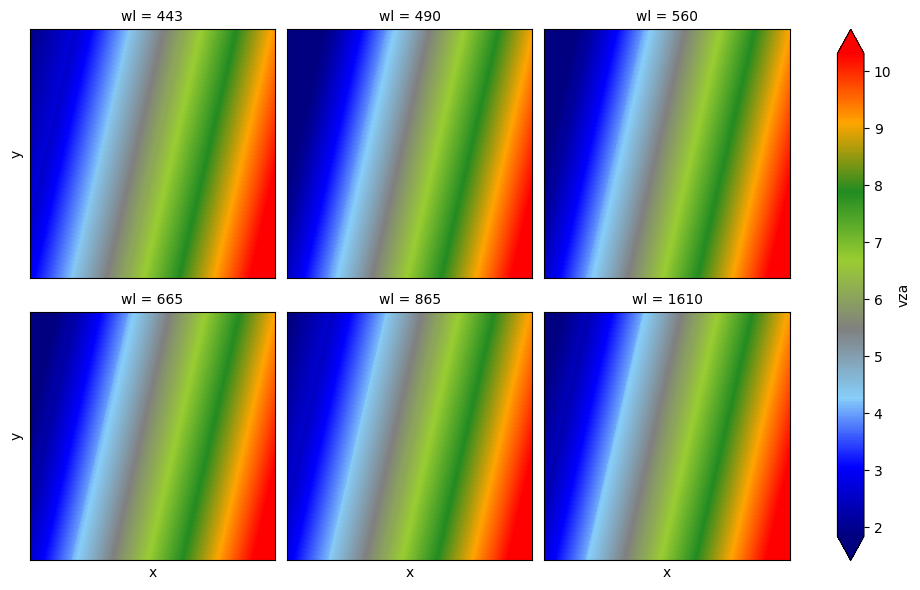

In [14]:
cmap = mpl.colors.LinearSegmentedColormap.from_list("",['navy', "blue", 'lightskyblue', 'gray', 'yellowgreen', 'forestgreen', 'orange', 'red'])
fig = l1c.prod.vza.plot.imshow(col='wl', cmap=cmap, col_wrap=3,  robust=True,subplot_kws=dict(xlabel='',xticks=[], yticks=[]))

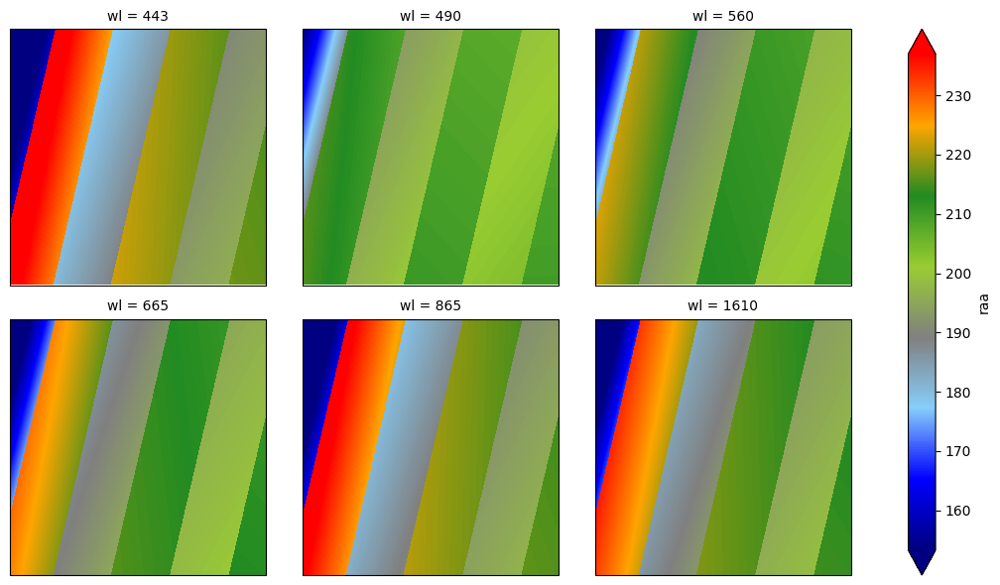

In [15]:
import cartopy.crs as ccrs
str_epsg = str(l1c.prod.bands.rio.crs)
zone = str_epsg[-2:]
is_south = str_epsg[2] == 7
proj = ccrs.UTM(zone, is_south)
fig = l1c.prod.raa.plot.imshow(col='wl', cmap=cmap, col_wrap=3, aspect=1.2, robust=True,subplot_kws=dict(projection=proj))

In [16]:
param='vza'
diff_vza = l1c.prod[param].sel(wl=490)-l1c.prod[param].sel(wl=865)
param='raa'
diff_raa = l1c.prod[param].sel(wl=490)-l1c.prod[param].sel(wl=865)


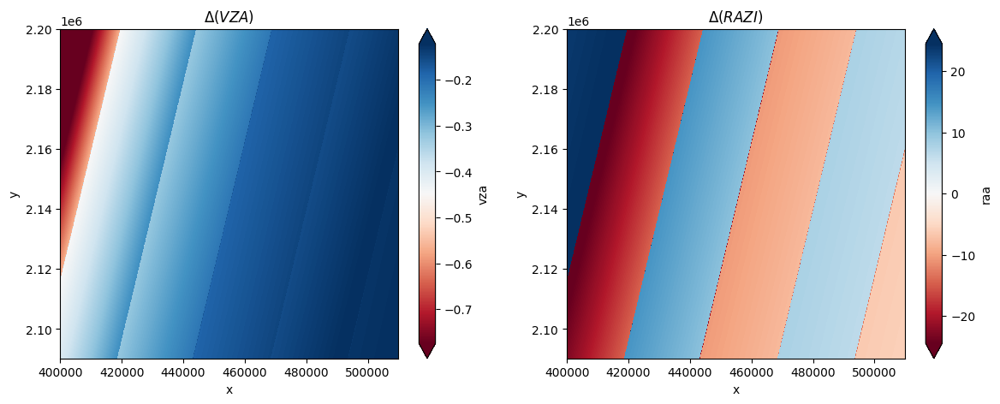

In [17]:
fig, axs = plt.subplots(ncols=2,figsize=(14,5))
diff_vza.plot.imshow(ax=axs[0],cmap=plt.cm.RdBu, robust=True)
axs[0].set_title('$\Delta (VZA)$')
diff_raa.plot.imshow(ax=axs[1],cmap=plt.cm.RdBu, robust=True)
axs[1].set_title('$\Delta (RAZI)$')
plt.show()

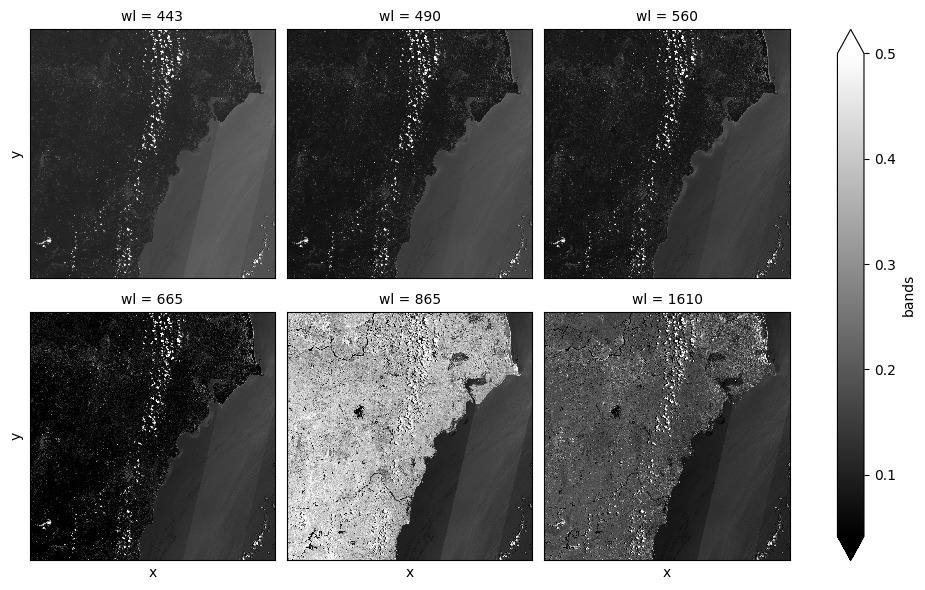

In [18]:

p = l1c.prod.bands.plot.imshow(col='wl', col_wrap=3,  vmax=0.5, robust=True, cmap=plt.cm.binary_r,subplot_kws=dict(xlabel='',xticks=[], yticks=[]))

In [19]:
import cartopy.crs as ccrs
str_epsg = str(l1c.epsg)
zone = str_epsg[-2:]
is_south = str_epsg[2] == 7
proj = ccrs.UTM(zone, is_south)

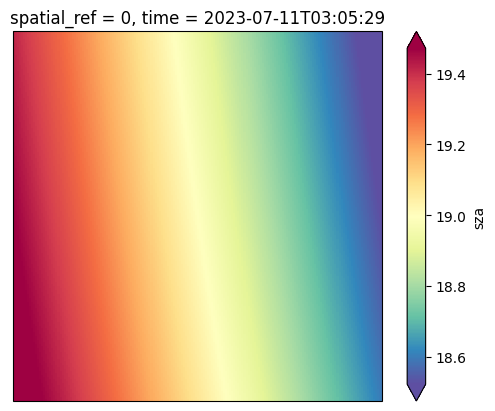

In [20]:
coarsening = 10
p = l1c.prod.sza[::coarsening, ::coarsening].plot.imshow(subplot_kws=dict(projection= proj), robust=True, cmap=plt.cm.Spectral_r)

In [21]:
# Get geographic projection and bounds
extent = l1c.extent

bounds = extent.bounds
extent_val = [bounds.minx[0], bounds.maxx[0]-40000, bounds.miny[0], bounds.maxy[0]-50000]
#extent_val = [bounds.minx[0], bounds.maxx[0], bounds.miny[0], bounds.maxy[0]]


Text(0.5, 1.0, '')

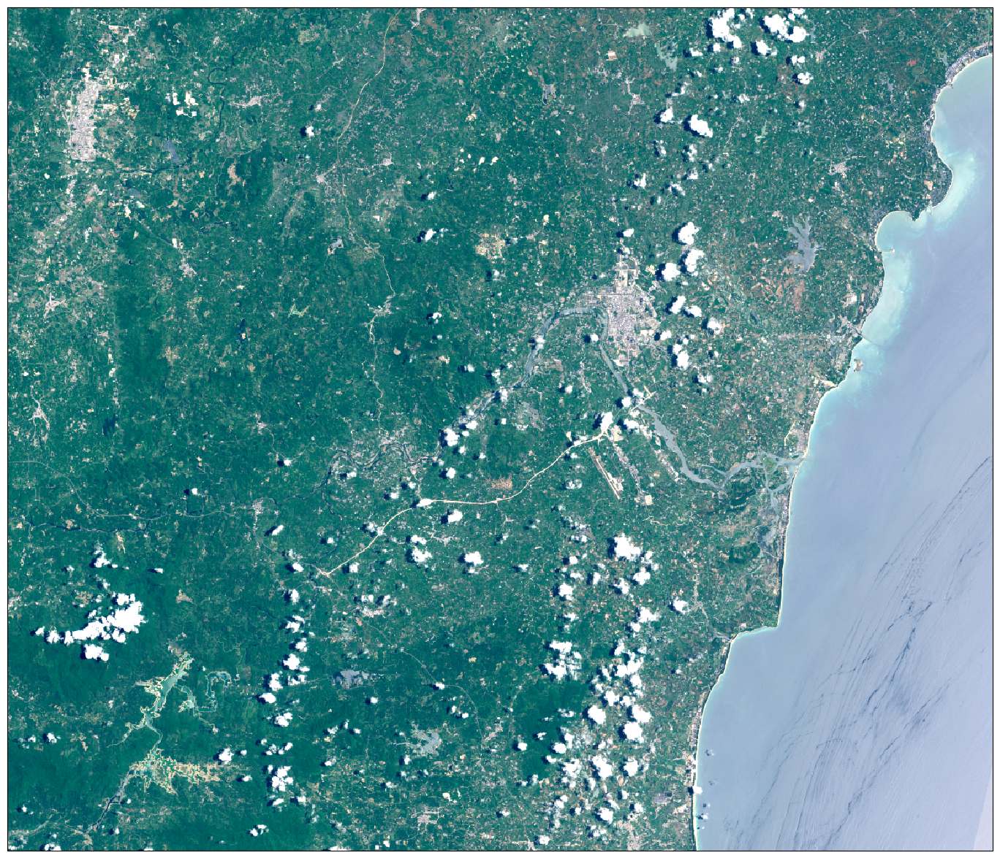

In [22]:
fig = plt.figure(figsize=(20, 15))
ax = plt.subplot(1, 1, 1, projection=proj)
ax.set_extent(extent_val, proj)
coarsening=1
brightness_factor = 3.5
(l1c.prod.bands[:, ::coarsening, ::coarsening].sel(wl=[665,560,490])**0.5**brightness_factor
).plot.imshow(rgb='wl', robust=True,subplot_kws=dict(projection= proj))
ax.set_title('')

In [23]:
#coarsening to save memory and speed (if greater than 1)
coarsening=1


# binary cmap
bcmap = mpl.colors.ListedColormap([(0,0,0,0),'steelblue'])

def sindex(R1,R2):
    return (R1-R2)/(R1+R2) 
    
def water_mask(ndwi, threshold=0):
    water = xr.where(ndwi > threshold, 1, 0)
    return water.where(~np.isnan(ndwi))

def plot_water_mask(ndwi,ax,threshold=0):
    water = water_mask(ndwi, threshold)
   
    water.plot.imshow(ax=ax, transform=proj, cmap=bcmap,
                                  cbar_kwargs={'ticks': [0, 1], 'shrink': shrink})
    ax.set_title(str(threshold)+' < NDWI')

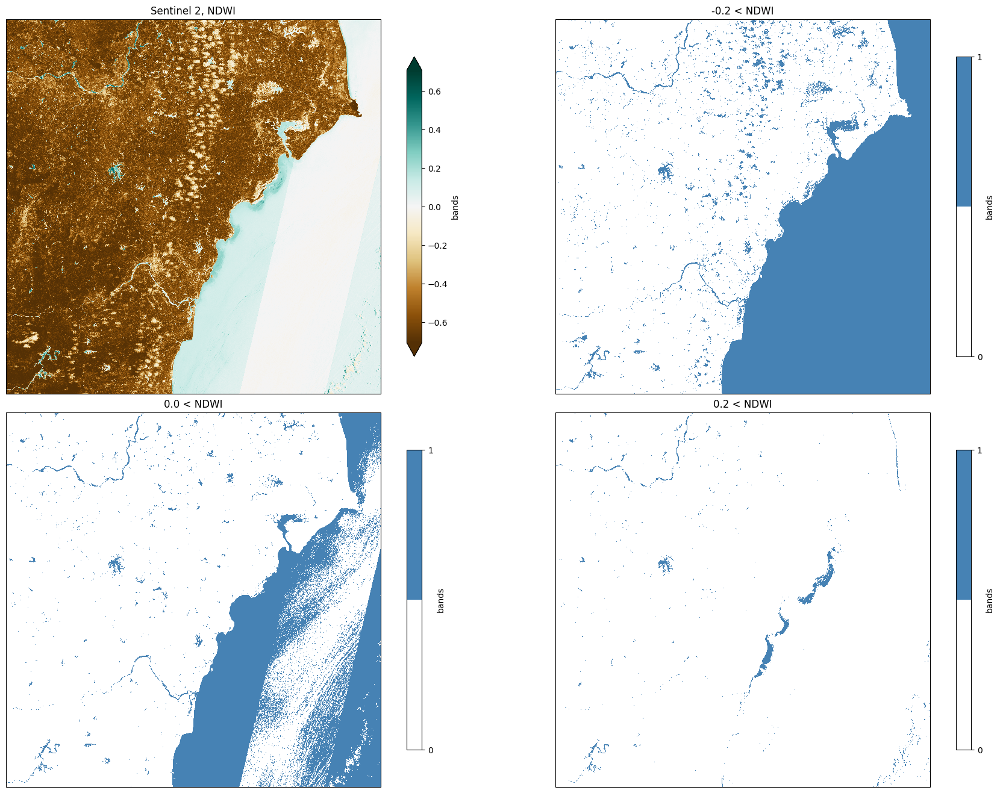

In [24]:
# Compute NDWI
green = l1c.prod.bands.sel(wl=565,method='nearest')
nir = l1c.prod.bands.sel(wl=865,method='nearest')
ndwi = (green - nir) / (green + nir)

fig = plt.figure(figsize=(20, 15))
fig.subplots_adjust(bottom=0.1, top=0.95, left=0.1, right=0.99,
                    hspace=0.05, wspace=0.05)
shrink = 0.8
    
ax = plt.subplot(2, 2, 1, projection=proj)
fig = ndwi[::coarsening, ::coarsening].plot.imshow( transform=proj, cmap=plt.cm.BrBG, robust=True,
                                   cbar_kwargs={'shrink': shrink})
# axes.coastlines(resolution='10m',linewidth=1)
ax.set_title('Sentinel 2, NDWI')

for i,threshold in enumerate([-0.2,0.,0.2]):
    ax = plt.subplot(2, 2, i+2, projection=proj)
    plot_water_mask(ndwi,ax,threshold=threshold)

plt.show()

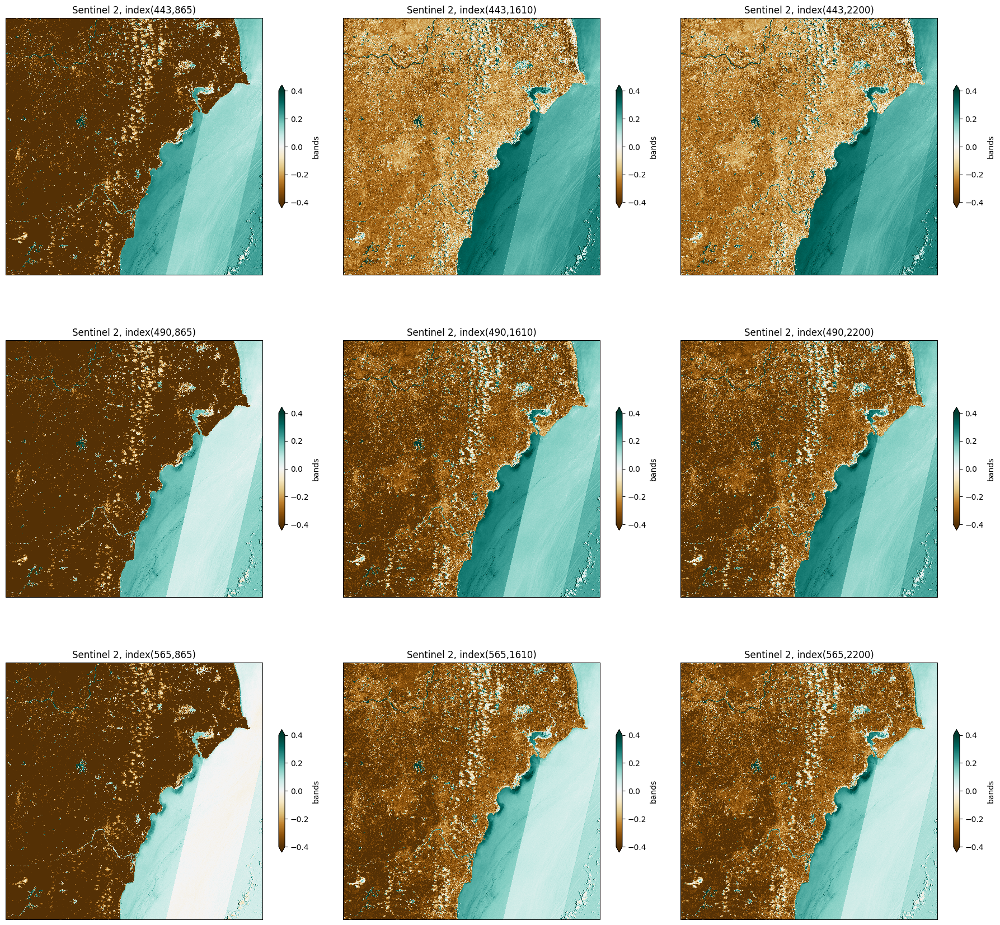

In [25]:

shrink = 0.4
ii=1
ncols=3
nrows=3
fig,axs= plt.subplots(nrows,ncols,figsize=(20, 20),sharey=True,sharex=True,subplot_kw={'projection':proj})
fig.subplots_adjust(bottom=0.1, top=0.95, left=0.1, right=0.99,
                    hspace=0.05, wspace=0.05)
axs_=axs.ravel()
for bands in ([443,865],[443,1610],[443,2200],[490,865],[490,1610],[490,2200],[565,865],[565,1610],[565,2200]):
    #ax = plt.subplot(nrows,ncols, ii, projection=proj)
    
    ax=axs_[ii-1]

    fig = sindex(l1c.prod.bands.sel(wl=bands[0],method='nearest'),l1c.prod.bands.sel(wl=bands[1],method='nearest')).plot.imshow(ax=ax, transform=proj, cmap=plt.cm.BrBG, vmin=-0.4,robust=True,
                                       cbar_kwargs={'shrink': shrink})
    ax.set_title('Sentinel 2, index({:.0f},{:.0f})'.format(*bands))
    ii+=1

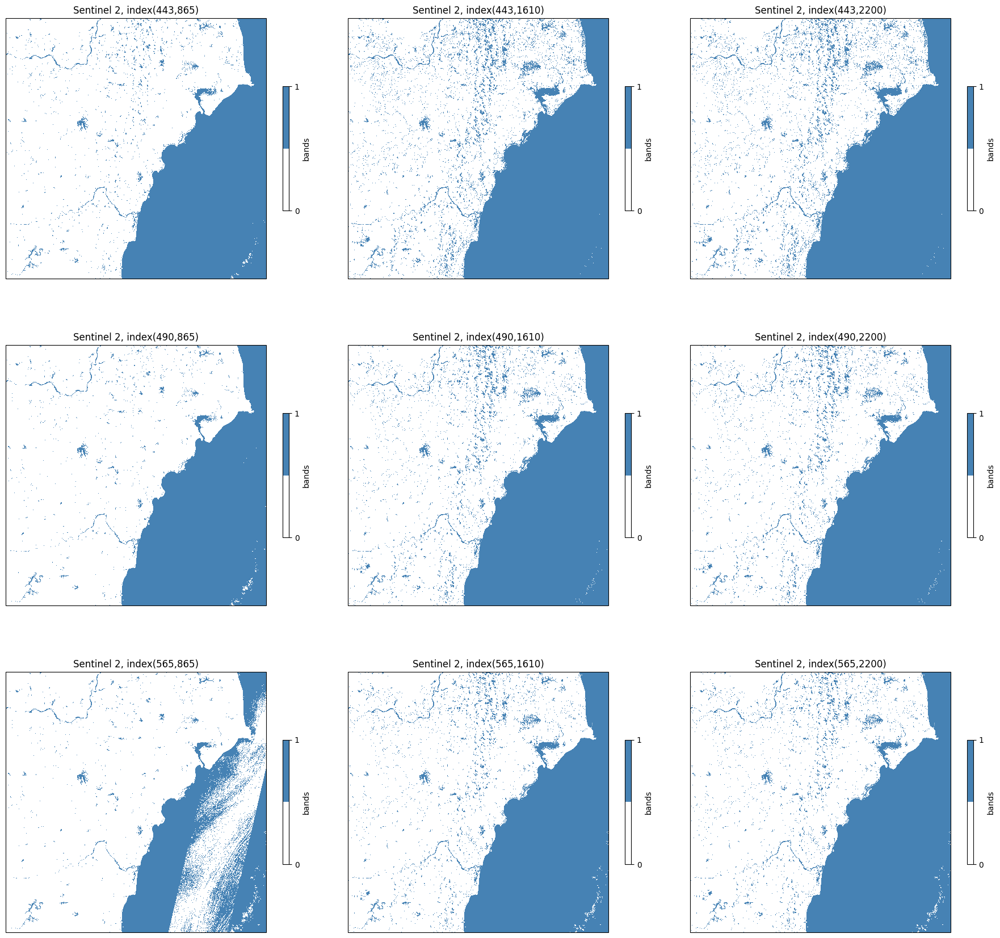

In [26]:
threshold=0
shrink = 0.4
ii=1
ncols=3
nrows=3
fig,axs= plt.subplots(nrows,ncols,figsize=(20, 20),sharey=True,sharex=True,subplot_kw={'projection':proj})
fig.subplots_adjust(bottom=0.1, top=0.95, left=0.1, right=0.99,
                    hspace=0.05, wspace=0.05)
axs_=axs.ravel()
for bands in ([443,865],[443,1610],[443,2200],[490,865],[490,1610],[490,2200],[565,865],[565,1610],[565,2200]):
    #ax = plt.subplot(nrows,ncols, ii, projection=proj)
    
    ax=axs_[ii-1]
    
    norm_index = sindex(l1c.prod.bands.sel(wl=bands[0],method='nearest'),l1c.prod.bands.sel(wl=bands[1],method='nearest'))
    plot_water_mask(norm_index,ax,threshold=threshold)
    ax.set_title('Sentinel 2, index({:.0f},{:.0f})'.format(*bands))
    ii+=1